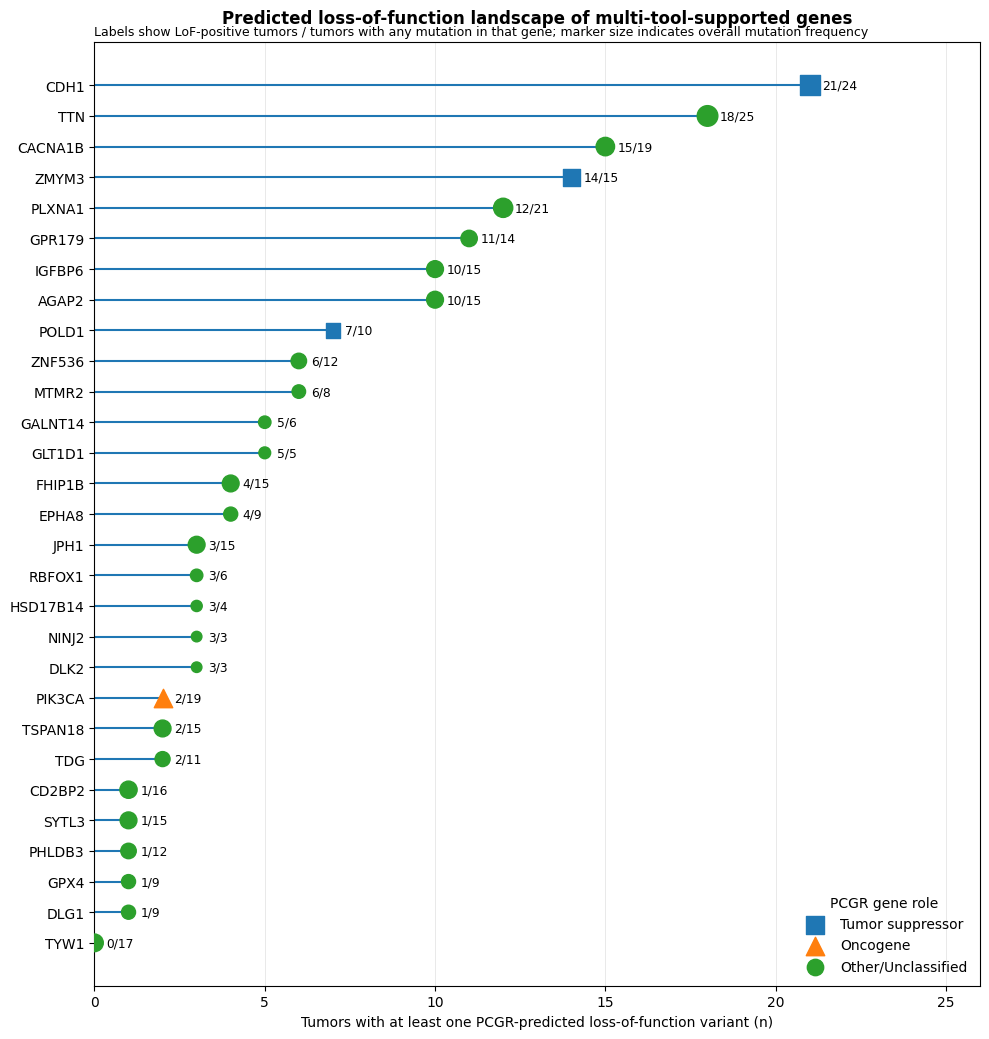

Completed successfully.
Cohort samples represented: 31
Summary table: /ix1/alee/LO_LAB/Personal/Rahul/pILC/WES/Downstream/PCGR/Compare_TumorOnly_vs_WithPON/Driver_Gene_Analysis/MultiTool_Consensus_29_Genes/MultiTool_29_Genes_LoF_plot_summary.tsv
PDF plot:     /ix1/alee/LO_LAB/Personal/Rahul/pILC/WES/Downstream/PCGR/Compare_TumorOnly_vs_WithPON/Driver_Gene_Analysis/MultiTool_Consensus_29_Genes/MultiTool_29_Genes_LoF_lollipop_LoF_over_mutated.pdf
PNG plot:     /ix1/alee/LO_LAB/Personal/Rahul/pILC/WES/Downstream/PCGR/Compare_TumorOnly_vs_WithPON/Driver_Gene_Analysis/MultiTool_Consensus_29_Genes/MultiTool_29_Genes_LoF_lollipop_LoF_over_mutated.png


In [2]:
"""
Create a gene-level summary and horizontal lollipop plot for predicted
loss-of-function variants among the 29 multi-tool-supported candidate genes.

Input:
    MultiTool_Consensus_29_Genes_PCGR_LOF_VAF_Oncogenicity.tsv

Outputs:
    MultiTool_29_Genes_LoF_plot_summary.tsv
    MultiTool_29_Genes_LoF_lollipop_LoF_over_mutated.pdf
    MultiTool_29_Genes_LoF_lollipop_LoF_over_mutated.png

Plot label:
    LoF-positive tumors / tumors with any mutation in that gene

Marker shape:
    Square   = tumor suppressor
    Triangle = oncogene
    Diamond  = dual oncogene/tumor-suppressor annotation
    Circle   = other/unclassified

Marker size:
    Overall mutation frequency across the cohort
"""

from __future__ import annotations

import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ============================================================
# 1. Paths
# ============================================================

INPUT_FILE = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/pILC/WES/Downstream/PCGR/"
    "Compare_TumorOnly_vs_WithPON/Driver_Gene_Analysis/"
    "MultiTool_Consensus_29_Genes/"
    "MultiTool_Consensus_29_Genes_PCGR_LOF_VAF_Oncogenicity.tsv"
)

OUTPUT_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/pILC/WES/Downstream/PCGR/"
    "Compare_TumorOnly_vs_WithPON/Driver_Gene_Analysis/"
    "MultiTool_Consensus_29_Genes"
)

SUMMARY_FILE = OUTPUT_DIR / "MultiTool_29_Genes_LoF_plot_summary.tsv"

PDF_FILE = (
    OUTPUT_DIR
    / "MultiTool_29_Genes_LoF_lollipop_LoF_over_mutated.pdf"
)

PNG_FILE = (
    OUTPUT_DIR
    / "MultiTool_29_Genes_LoF_lollipop_LoF_over_mutated.png"
)

SAMPLE_COLUMN = "SAMPLE_FOLDER"


# ============================================================
# 2. Fixed 29-gene set
# ============================================================

CONSENSUS_GENES = [
    "AGAP2",
    "CD2BP2",
    "DLK2",
    "HSD17B14",
    "MTMR2",
    "NINJ2",
    "PLXNA1",
    "POLD1",
    "CACNA1B",
    "CDH1",
    "DLG1",
    "EPHA8",
    "FHIP1B",
    "GALNT14",
    "GLT1D1",
    "GPR179",
    "GPX4",
    "IGFBP6",
    "JPH1",
    "PHLDB3",
    "PIK3CA",
    "RBFOX1",
    "SYTL3",
    "TDG",
    "TSPAN18",
    "TTN",
    "TYW1",
    "ZMYM3",
    "ZNF536",
]

if len(set(CONSENSUS_GENES)) != 29:
    raise RuntimeError("The consensus gene list must contain 29 unique genes.")


# ============================================================
# 3. Helper functions
# ============================================================

def to_bool(series: pd.Series) -> pd.Series:
    """
    Convert common TRUE/FALSE representations to Boolean values.
    Blank, missing, and unrecognized values are treated as FALSE.
    """
    return (
        series.astype(str)
        .str.strip()
        .str.lower()
        .map(
            {
                "true": True,
                "t": True,
                "1": True,
                "yes": True,
                "false": False,
                "f": False,
                "0": False,
                "no": False,
            }
        )
        .fillna(False)
        .astype(bool)
    )


def require_columns(data: pd.DataFrame, columns: list[str]) -> None:
    """Stop with a clear error if required columns are absent."""
    missing = [column for column in columns if column not in data.columns]

    if missing:
        raise ValueError(
            "Required columns are missing from the input file: "
            + ", ".join(missing)
        )


# ============================================================
# 4. Read and validate input
# ============================================================

if not INPUT_FILE.is_file():
    raise FileNotFoundError(f"Input file was not found:\n{INPUT_FILE}")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(
    INPUT_FILE,
    sep="\t",
    dtype=str,
    low_memory=False,
)

required_columns = [
    SAMPLE_COLUMN,
    "SYMBOL",
    "LOSS_OF_FUNCTION",
    "ONCOGENE",
    "TUMOR_SUPPRESSOR",
]

require_columns(data, required_columns)

data["SYMBOL"] = data["SYMBOL"].astype(str).str.strip().str.upper()
data[SAMPLE_COLUMN] = data[SAMPLE_COLUMN].astype(str).str.strip()

data = data[
    data["SYMBOL"].isin(CONSENSUS_GENES)
    & data[SAMPLE_COLUMN].ne("")
    & data[SAMPLE_COLUMN].ne("nan")
].copy()

if data.empty:
    raise RuntimeError(
        "No rows from the 29 consensus genes were found in the input."
    )

data["LOSS_OF_FUNCTION_BOOL"] = to_bool(data["LOSS_OF_FUNCTION"])
data["ONCOGENE_BOOL"] = to_bool(data["ONCOGENE"])
data["TUMOR_SUPPRESSOR_BOOL"] = to_bool(data["TUMOR_SUPPRESSOR"])

total_cohort_samples = data[SAMPLE_COLUMN].nunique()

if total_cohort_samples == 0:
    raise RuntimeError("No valid sample identifiers were found.")


# ============================================================
# 5. Build gene-level summary
# ============================================================

summary_rows: list[dict[str, object]] = []

for gene in CONSENSUS_GENES:
    gene_data = data[data["SYMBOL"] == gene].copy()

    if gene_data.empty:
        summary_rows.append(
            {
                "Gene": gene,
                "Mutated_samples": 0,
                "Mutation_frequency_percent": 0.0,
                "LoF_samples": 0,
                "LoF_frequency_percent_cohort": 0.0,
                "LoF_percent_among_mutated": np.nan,
                "LoF_variant_rows": 0,
                "Gene_role": "Other/Unclassified",
            }
        )
        continue

    lof_data = gene_data[gene_data["LOSS_OF_FUNCTION_BOOL"]].copy()

    mutated_samples = gene_data[SAMPLE_COLUMN].nunique()
    lof_samples = lof_data[SAMPLE_COLUMN].nunique()

    oncogene_any = bool(gene_data["ONCOGENE_BOOL"].any())
    tumor_suppressor_any = bool(
        gene_data["TUMOR_SUPPRESSOR_BOOL"].any()
    )

    if oncogene_any and tumor_suppressor_any:
        gene_role = "Dual"
    elif tumor_suppressor_any:
        gene_role = "Tumor suppressor"
    elif oncogene_any:
        gene_role = "Oncogene"
    else:
        gene_role = "Other/Unclassified"

    summary_rows.append(
        {
            "Gene": gene,
            "Mutated_samples": mutated_samples,
            "Mutation_frequency_percent": (
                100.0 * mutated_samples / total_cohort_samples
            ),
            "LoF_samples": lof_samples,
            "LoF_frequency_percent_cohort": (
                100.0 * lof_samples / total_cohort_samples
            ),
            "LoF_percent_among_mutated": (
                100.0 * lof_samples / mutated_samples
                if mutated_samples > 0
                else np.nan
            ),
            "LoF_variant_rows": len(lof_data),
            "Gene_role": gene_role,
        }
    )

summary = pd.DataFrame(summary_rows)

summary = summary.sort_values(
    ["LoF_samples", "Mutated_samples", "Gene"],
    ascending=[False, False, True],
).reset_index(drop=True)

summary.to_csv(
    SUMMARY_FILE,
    sep="\t",
    index=False,
    na_rep="",
)


# ============================================================
# 6. Generate horizontal lollipop plot
# ============================================================

plot_data = summary.sort_values(
    ["LoF_samples", "Mutated_samples", "Gene"],
    ascending=[True, True, True],
).reset_index(drop=True)

role_markers = {
    "Tumor suppressor": "s",
    "Oncogene": "^",
    "Dual": "D",
    "Other/Unclassified": "o",
}

figure, axis = plt.subplots(figsize=(10, 10.5))
y_positions = np.arange(len(plot_data))

# Lollipop stems
for y_position, lof_count in zip(
    y_positions,
    plot_data["LoF_samples"],
):
    axis.hlines(
        y=y_position,
        xmin=0,
        xmax=lof_count,
        linewidth=1.5,
    )

# Markers grouped by PCGR gene role
for role, marker in role_markers.items():
    role_data = plot_data[plot_data["Gene_role"] == role]

    if role_data.empty:
        continue

    marker_sizes = (
        35
        + 2.3
        * role_data["Mutation_frequency_percent"].to_numpy()
    )

    axis.scatter(
        role_data["LoF_samples"],
        role_data.index.to_numpy(),
        s=marker_sizes,
        marker=marker,
        label=role,
        zorder=3,
    )

# Labels: LoF-positive tumors / all mutated tumors for each gene
for row_index, row in plot_data.iterrows():
    axis.text(
        row["LoF_samples"] + 0.35,
        row_index,
        f'{int(row["LoF_samples"])}/{int(row["Mutated_samples"])}',
        va="center",
        fontsize=8.8,
    )

axis.set_yticks(y_positions)
axis.set_yticklabels(plot_data["Gene"])
axis.set_xlabel(
    "Tumors with at least one PCGR-predicted "
    "loss-of-function variant (n)"
)
axis.set_ylabel("")

axis.set_title(
    "Predicted loss-of-function landscape of "
    "multi-tool-supported genes",
    pad=14,
    fontweight="bold",
)

axis.text(
    0.0,
    1.005,
    (
        "Labels show LoF-positive tumors / tumors with any "
        "mutation in that gene; marker size indicates overall "
        "mutation frequency"
    ),
    transform=axis.transAxes,
    fontsize=9,
    va="bottom",
)

maximum_lof = int(plot_data["LoF_samples"].max())
axis.set_xlim(0, maximum_lof + 5)

axis.grid(
    axis="x",
    linewidth=0.5,
    alpha=0.4,
)

axis.legend(
    title="PCGR gene role",
    loc="lower right",
    frameon=False,
)

figure.tight_layout()

figure.savefig(
    PDF_FILE,
    bbox_inches="tight",
)

figure.savefig(
    PNG_FILE,
    dpi=600,
    bbox_inches="tight",
)

# Display when run interactively; harmless in batch mode.
plt.show()
plt.close(figure)


# ============================================================
# 7. Completion summary
# ============================================================

print("Completed successfully.")
print(f"Cohort samples represented: {total_cohort_samples}")
print(f"Summary table: {SUMMARY_FILE}")
print(f"PDF plot:     {PDF_FILE}")
print(f"PNG plot:     {PNG_FILE}")